# 05 · Variables nuevas (experimento #3)

**Etapa 5 del plan** (`fichas/etapa_5_variables_nuevas.md`). Mide, bloque por bloque, si las variables nuevas **suben la ganancia**, con el mismo protocolo del `02` y el `04`: 10 semillas, meseta suavizada, ganancia solo con `BAJA+2` y comparación pareada con Wilcoxon.

| Bloque | Qué es | Variables |
|---|---|---:|
| **B1** | Del mismo mes (TP4): uso del límite de tarjeta, saldo total de tarjetas, saldo / rentabilidad, ranking de `ctrx_quarter` y de `mcuentas_saldo` dentro del mes | 6 |
| **B2** | Historia del TP4: `lag_1`, `lag_2`, `delta_1`, `avg3`, `min3`, `max3` y `slope3` de 8 variables. **Ventana corregida a 3 meses** (el TP4 tomaba 4) | 56 |
| **B3** | Señales del video de Miranda: comisión, sueldo, consumo de tarjeta comparado con los meses anteriores, saldo, caja de ahorro, sucursal y call center | 17 |
| **B4** | Los 73 montos **reemplazados** por su ranking dentro del mes (contra la inflación, el aguinaldo y la suba de la comisión) | 73 reemplazadas |
| **B4c** | Igual que B4, pero con el ranking **con el cero fijo** (cátedra 2024, `rank_cero_fijo`): el 0 queda en 0, los positivos van a (0, 1] y los negativos a [−1, 0). Conserva el cero y el signo. No se combina con B4 | 73 reemplazadas |
| **B5** | Lag 1 y delta 1 de **todas** las variables ("meter todo", Bolaños; flujo de la cátedra 2024). Para los montos, sobre su ranking con el cero fijo, para que el drift no vuelva a entrar por el lag. No repite los que ya están en B2 y B3 | 293 |

**Pruebas:**
- **A** (entrena `202103`–`202104`, predice `202106`) y **B** (entrena `202103`, predice `202105`), como siempre.
- **C** (entrena `202103`–`202105`, predice `202106`), **solo de referencia** y solo para los bloques con historia (B2, B3, B5). No tiene el hueco de dos meses, pero es la única prueba con historia completa en el entrenamiento: B entrena solo con marzo, donde toda la historia está vacía.

**Cada bloque se compara contra la base**, y las combinaciones (`COMBINACIONES`) también **contra la `REFERENCIA`**, la mejor combinación hasta ahora (`B2+B3+B4`). Lo ya corrido no se repite.

## 1. Parámetros

- **`BASE` (obligatoria):** `'linea_base'` (las variables del `02`) o una variante del `04`, por ejemplo `'V5'`. Las curvas de la base en A y B se leen del `02` o del `04`; la de C se corre acá.
- **`MODO_RAPIDO = True`** corre 1 semilla, para medir el tiempo. Con `False` corre las 10. Retoma si se corta.
- **`COMBINACIONES`:** una lista de combinaciones de bloques, por ejemplo `[['B2', 'B3', 'B4'], ['B2', 'B3', 'B4c']]`. Lo ya corrido no se repite.
- **`REFERENCIA`:** la combinación contra la que se comparan las demás, además de la base (tiene que estar en `COMBINACIONES`).
- **`REHACER_FE`:** el parquet de variables nuevas se arma una sola vez. Si cambia la definición de un bloque, se rearma solo.

In [56]:
from itertools import product
from pathlib import Path
import json
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

# --- Parámetros -------------------------------------------------------------
MODO_RAPIDO = False              # True: 1 semilla (medir tiempos) · False: 10 semillas
BASE = 'V5'                     # <- OBLIGATORIO: 'linea_base' o una variante del 04 (decidido: 'V5')
CONFIG = 'z470_bajas'           # decisión 2 de la ficha
BLOQUES_A_CORRER = ['B1', 'B2', 'B3', 'B4']          # cada uno solo, contra la base (ya corridos: no se repiten)
COMBINACIONES = [['B2', 'B3', 'B4'],                   # la adoptada (ya corrida)
                 ['B2', 'B3', 'B4c'],                  # paso 2: ranking con el cero fijo
                 ['B2', 'B3', 'B4c', 'B5'],            # paso 2: + lag 1 y delta 1 de todas las variables
                 ['B2', 'B3', 'B4', 'B5']]             # paso 2: ranking simple + historia de todas
REFERENCIA = 'B2+B3+B4'         # la mejor hasta ahora: las combinaciones se comparan también contra esta
PRUEBA_C = {'train': [202103, 202104, 202105], 'test': 202106}   # referencia: sin el hueco de dos meses
REHACER_FE = False              # True: vuelve a armar el parquet de variables nuevas

BASE_PARQUET = Path('../data/competencia_01_base.parquet')
FE_PARQUET = Path('../data/competencia_01_fe.parquet')
EXP02 = Path('../exp/02_linea_base')
EXP04 = Path('../exp/04_drift')
EXP = Path('../exp/05_variables')
CURVAS = EXP / 'curvas'
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

assert BASE_PARQUET.exists(), 'Falta el dataset base: correr 01_pipeline_base'
assert (EXP02 / 'configuraciones.json').exists(), 'Falta la salida del 02'
CURVAS.mkdir(parents=True, exist_ok=True)

config02 = json.loads((EXP02 / 'configuraciones.json').read_text())
HIPERPARAMETROS = config02['hiperparametros']
CLASES = config02['clases']
PRUEBAS = {**config02['pruebas'], 'C': PRUEBA_C}
CORTES = config02['cortes']
VENTANA_SUAVIZADO = config02['ventana_suavizado']
GANANCIA_ACIERTO, COSTO_ESTIMULO = config02['ganancia_acierto'], config02['costo_estimulo']

SEMILLAS_BACKTEST = json.loads((EXP02 / 'semillas.json').read_text())['semillas'][:10]
SEMILLAS_A_USAR = SEMILLAS_BACKTEST[:1] if MODO_RAPIDO else SEMILLAS_BACKTEST

# La base se elige siempre a propósito (decisión 1 de la ficha)
variantes_04 = json.loads((EXP04 / 'variantes.json').read_text()) if (EXP04 / 'variantes.json').exists() else {}
assert BASE == 'linea_base' or (BASE in variantes_04 and BASE != 'V0'), \
    f"BASE tiene que ser 'linea_base' o una de {sorted(set(variantes_04) - {'V0'})}"
DEF_BASE = {'excluir': [], 'na_en_mes': {}} if BASE == 'linea_base' else variantes_04[BASE]

HIPER, CLASE = CONFIG.split('_', 1)
assert HIPER in HIPERPARAMETROS and CLASE in CLASES, f'Configuración desconocida: {CONFIG}'

HISTORIA = {'B2', 'B3', 'B5'}    # bloques que usan meses anteriores
TODOS = {'B1', 'B2', 'B3', 'B4', 'B4c', 'B5'}
assert set(BLOQUES_A_CORRER) | {b for c in COMBINACIONES for b in c} <= TODOS
assert not any({'B4', 'B4c'} <= set(c) for c in COMBINACIONES), 'B4 y B4c reemplazan los mismos montos: van por separado'
NOMBRES = list(BLOQUES_A_CORRER) + ['+'.join(sorted(c)) for c in COMBINACIONES]
assert REFERENCIA is None or REFERENCIA in NOMBRES, 'REFERENCIA tiene que estar entre las corridas'


def pruebas_de(nombre):
    # A y B siempre; C también si incluye un bloque con historia
    return ['A', 'B'] + (['C'] if HISTORIA & set(nombre.split('+')) else [])


NECESITA_C = any('C' in pruebas_de(n) for n in NOMBRES)
print(f'>>> BASE: {BASE} · excluye: {DEF_BASE["excluir"] or "—"} · NA: {DEF_BASE["na_en_mes"] or "—"}')
print(f'Configuración: {CONFIG} · semillas: {len(SEMILLAS_A_USAR)} · a correr: {NOMBRES}')

>>> BASE: V5 · excluye: ['Master_fultimo_cierre', 'Visa_fultimo_cierre', 'Master_Finiciomora', 'Visa_Finiciomora'] · NA: {'ccajas_depositos': [202105]}
Configuración: z470_bajas · semillas: 10 · a correr: ['B1', 'B2', 'B3', 'B4', 'B2+B3+B4', 'B2+B3+B4c', 'B2+B3+B4c+B5', 'B2+B3+B4+B5']


## 2. Variables nuevas en SQL

Todo se arma en DuckDB sobre el parquet base, con ventanas que **solo miran hacia atrás**:
- `vc`: las filas del cliente ordenadas por mes (para `lag`);
- `v3`: los últimos **3** meses, el actual incluido (`rows between 2 preceding and current row`);
- `vprev3`: los 3 meses **anteriores**, sin el actual (para comparar el mes contra su historia).

Detalles:
- **Rankings** (`percent_rank` dentro del mes): los nulos quedan nulos y no corren el ranking de los demás.
- **Contadores de 3 meses** (`meses_pagando_comision_3`, `meses_con_sueldo_3`): quedan vacíos si el cliente tiene menos de 3 meses de historia. Así no se confunde "pagó 1 de 1 mes" con "pagó 1 de 3".
- **Flags contra el mes anterior** (`empieza_comision`, `perdio_sueldo`, `cae_saldo`): vacíos si no hay mes anterior.
- **B1–B4 se arman en SQL; B4c y B5, en numpy.** Con ~150 rankings y ~300 lags en una sola consulta, DuckDB se quedaba sin memoria (cada ranking ordena todas las filas con todas sus columnas). En numpy es directo, y el parquet se escribe igual con DuckDB.
- **Ranking con el cero fijo** (B4c): el 0 queda en 0; los positivos, su ranking entre los positivos del mes dividido por cuántos son (en (0, 1]); los negativos, lo mismo con signo menos, contando desde el más cercano a 0 (el más negativo queda en −1). Empates: el rango mayor.
- **Lags de B5:** por cliente, la fila anterior ordenada por mes, igual que el `lag` de SQL (en los intermitentes, el último mes en que estuvieron).
- **B5:** `lag_1`/`delta_1` de cada variable que no es monto, y `l1_rk0_`/`d1_rk0_` del ranking con el cero fijo de cada monto. Sin `numero_de_cliente`, `cliente_antiguedad` ni `cliente_edad`, y sin los que ya están en B2 y B3.
- Si la base saca una variable (por ejemplo, los préstamos), **sus derivadas tampoco entran** (`FUENTES`).

In [57]:
con = duckdb.connect()
con.execute('CREATE OR REPLACE MACRO ratio_seguro(a, b) AS CASE WHEN b IS NULL OR b = 0 THEN NULL ELSE ifnull(a, 0) / b END')
con.execute('CREATE OR REPLACE MACRO suma_sin_null(a, b) AS ifnull(a, 0) + ifnull(b, 0)')

COLUMNAS_BASE = con.sql(f"describe select * from read_parquet('{BASE_PARQUET.as_posix()}')").df()['column_name'].tolist()
MONTOS = [c for c in COLUMNAS_BASE if c.startswith(('m', 'Visa_m', 'Master_m'))]

BLOQUES = {b: [] for b in ['B1', 'B2', 'B3', 'B4', 'B4c', 'B5']}
FUENTES = {}          # variable nueva -> columnas originales que usa
lineas_sql = []       # B1–B4 (SQL)
NUMPY = {}            # B4c y B5: variable nueva -> (tipo, columna de origen)


def nueva(bloque, nombre, sql, fuentes):
    BLOQUES[bloque].append(nombre)
    FUENTES[nombre] = sorted(fuentes)
    lineas_sql.append(f'({sql})::FLOAT as {nombre}')


def nueva_numpy(bloque, nombre, tipo, origen, fuentes):
    BLOQUES[bloque].append(nombre)
    FUENTES[nombre] = sorted(fuentes)
    NUMPY[nombre] = (tipo, origen)


def rank_mes(x):
    return f'case when {x} is null then null else percent_rank() over (partition by foto_mes, {x} is null order by {x}) end'


def lag(x, k=1):
    return f'lag({x}, {k}) over vc'


def flag_vs_anterior(x, condicion):
    # 1/0 según la condición; vacío si falta el mes actual o el anterior
    return f'case when {x} is null or {lag(x)} is null then null when {condicion} then 1 else 0 end'


def meses_de_3(condicion):
    return f'case when count(*) over v3 = 3 then sum(case when {condicion} then 1 else 0 end) over v3 end'


# B1 · del mismo mes (TP4)
nueva('B1', 'ratio_uso_limite_visa', 'ratio_seguro(mtarjeta_visa_consumo, Visa_mlimitecompra)', ['mtarjeta_visa_consumo', 'Visa_mlimitecompra'])
nueva('B1', 'ratio_uso_limite_master', 'ratio_seguro(mtarjeta_master_consumo, Master_mlimitecompra)', ['mtarjeta_master_consumo', 'Master_mlimitecompra'])
nueva('B1', 'tc_saldo_total', 'suma_sin_null(Master_msaldototal, Visa_msaldototal)', ['Master_msaldototal', 'Visa_msaldototal'])
nueva('B1', 'ratio_saldo_rentabilidad', 'ratio_seguro(mcuentas_saldo, mrentabilidad_annual)', ['mcuentas_saldo', 'mrentabilidad_annual'])
nueva('B1', 'prank_ctrx_quarter', rank_mes('ctrx_quarter'), ['ctrx_quarter'])
nueva('B1', 'prank_mcuentas_saldo', rank_mes('mcuentas_saldo'), ['mcuentas_saldo'])

# B2 · historia del TP4, con la ventana corregida a 3 meses
CAMPOS_B2 = ['ctrx_quarter', 'mcuentas_saldo', 'mpasivos_margen', 'mcaja_ahorro',
             'mprestamos_personales', 'mcuenta_corriente', 'mrentabilidad_annual', 'mtarjeta_visa_consumo']
for c in CAMPOS_B2:
    nueva('B2', f'lag_1_{c}', lag(c), [c])
    nueva('B2', f'lag_2_{c}', lag(c, 2), [c])
    nueva('B2', f'delta_1_{c}', f'{c} - {lag(c)}', [c])
    nueva('B2', f'avg3_{c}', f'avg({c}) over v3', [c])
    nueva('B2', f'min3_{c}', f'min({c}) over v3', [c])
    nueva('B2', f'max3_{c}', f'max({c}) over v3', [c])
    nueva('B2', f'slope3_{c}', f'regr_slope({c}, cliente_antiguedad) over v3', [c, 'cliente_antiguedad'])

# B3 · señales del video de Miranda (informe técnico §6–7)
cm = 'mcomisiones_mantenimiento'
nueva('B3', 'empieza_comision', flag_vs_anterior(cm, f'{cm} > 0 and {lag(cm)} <= 0'), [cm])
nueva('B3', 'meses_pagando_comision_3', meses_de_3(f'{cm} > 0'), [cm])
nueva('B3', f'delta_1_{cm}', f'{cm} - {lag(cm)}', [cm])
for c in ['cpayroll_trx', 'mpayroll']:
    nueva('B3', f'lag_1_{c}', lag(c), [c])
    nueva('B3', f'lag_2_{c}', lag(c, 2), [c])
nueva('B3', 'perdio_sueldo', flag_vs_anterior('cpayroll_trx', f"{lag('cpayroll_trx')} > 0 and cpayroll_trx = 0"), ['cpayroll_trx'])
nueva('B3', 'meses_con_sueldo_3', meses_de_3('cpayroll_trx > 0'), ['cpayroll_trx'])
nueva('B3', 'consumo_visa_vs_prom3', 'ratio_seguro(mtarjeta_visa_consumo, avg(mtarjeta_visa_consumo) over vprev3)', ['mtarjeta_visa_consumo'])
for c in ['ctarjeta_visa_transacciones', 'ctarjeta_master_transacciones']:
    nueva('B3', f'delta_1_{c}', f'{c} - {lag(c)}', [c])
nueva('B3', 'cae_saldo', flag_vs_anterior('mcuentas_saldo', f"mcuentas_saldo < {lag('mcuentas_saldo')}"), ['mcuentas_saldo'])
tiene_ca = 'case when mcaja_ahorro is null then null when mcaja_ahorro > 0 then 1 else 0 end'
nueva('B3', 'tiene_caja_ahorro', tiene_ca, ['mcaja_ahorro'])
nueva('B3', 'tenia_caja_ahorro', lag(tiene_ca), ['mcaja_ahorro'])
for c in ['ccajas_consultas', 'ccallcenter_transacciones']:
    nueva('B3', f'delta_1_{c}', f'{c} - {lag(c)}', [c])

# B4 · montos → ranking dentro del mes (reemplazan al monto)
for c in MONTOS:
    nueva('B4', f'rk_{c}', rank_mes(c), [c])

# B4c · montos → ranking con el cero fijo (reemplazan al monto) · numpy
for c in MONTOS:
    nueva_numpy('B4c', f'rk0_{c}', 'rank0', c, [c])

# B5 · lag 1 y delta 1 de todas las variables (montos: sobre su ranking con el cero fijo) · numpy
ya_hechas = set(BLOQUES['B2']) | set(BLOQUES['B3'])
for c in COLUMNAS_BASE:
    if c in ('numero_de_cliente', 'foto_mes', 'clase_ternaria', 'cliente_antiguedad', 'cliente_edad'):
        continue
    origen = f'rk0_{c}' if c in MONTOS else c
    prefijos = ('l1_rk0_', 'd1_rk0_') if c in MONTOS else ('lag_1_', 'delta_1_')
    for prefijo, tipo in zip(prefijos, ('lag', 'delta')):
        nombre = f'{prefijo}{c}'
        if nombre not in ya_hechas:
            nueva_numpy('B5', nombre, tipo, origen, [c])


def rank_cero_fijo(x, meses):
    # 0 → 0; positivos: rango (empates: el mayor) / cantidad de positivos del mes; negativos: igual, con signo menos
    s, out = pd.Series(x), np.full(len(x), np.nan, dtype=np.float32)
    out[s.to_numpy() == 0] = 0
    for signo in (1, -1):
        m = (s * signo > 0).to_numpy()
        out[m] = signo * (s[m] * signo).groupby(meses[m]).rank(method='max', pct=True).to_numpy()
    return out

# Control 2 de la ficha
cantidades = {b: len(v) for b, v in BLOQUES.items()}
print('Variables nuevas por bloque:', cantidades)
assert cantidades == {'B1': 6, 'B2': 56, 'B3': 17, 'B4': 73, 'B4c': 73, 'B5': 293}
NUEVAS = [v for b in BLOQUES.values() for v in b]
assert len(NUEVAS) == len(set(NUEVAS)) and not set(NUEVAS) & set(COLUMNAS_BASE)

esperadas = COLUMNAS_BASE + [v for v in NUEVAS if v not in NUMPY] + [v for v in NUEVAS if v in NUMPY]
existentes = (con.sql(f"describe select * from read_parquet('{FE_PARQUET.as_posix()}')").df()['column_name'].tolist()
              if FE_PARQUET.exists() else None)
if REHACER_FE or existentes != esperadas:
    t0 = time.time()
    separador = '\n        , '
    # B1–B4 en SQL
    tabla = con.sql(f'''
        select * exclude (file_row_number)
        , {separador.join(lineas_sql)}
        from read_parquet('{BASE_PARQUET.as_posix()}', file_row_number = true)
        window
            vc as (partition by numero_de_cliente order by foto_mes),
            v3 as (partition by numero_de_cliente order by foto_mes rows between 2 preceding and current row),
            vprev3 as (partition by numero_de_cliente order by foto_mes rows between 3 preceding and 1 preceding)
        order by file_row_number          -- mismo orden de filas que el parquet base (LightGBM depende del orden)
    ''').df()
    print(f'B1–B4 (SQL): {tabla.shape[1]} columnas · {time.time() - t0:.0f} s')

    # B4c y B5 en numpy
    meses_fe = tabla['foto_mes'].to_numpy()
    orden = np.lexsort((meses_fe, tabla['numero_de_cliente'].to_numpy()))     # por cliente y mes
    cli = tabla['numero_de_cliente'].to_numpy()[orden]
    sin_anterior = np.r_[True, cli[1:] != cli[:-1]]                           # primera fila de cada cliente

    def lag_1(v):
        vs = v[orden].astype(np.float32)
        l = np.r_[np.float32(np.nan), vs[:-1]]
        l[sin_anterior] = np.nan
        out = np.empty_like(l)
        out[orden] = l
        return out

    nuevas_numpy = {}
    for nombre, (tipo, origen) in NUMPY.items():
        if tipo == 'rank0':
            nuevas_numpy[nombre] = rank_cero_fijo(tabla[origen].to_numpy(), meses_fe)
    for nombre, (tipo, origen) in NUMPY.items():
        if tipo != 'rank0':
            v = (nuevas_numpy[origen] if origen in nuevas_numpy else tabla[origen].to_numpy()).astype(np.float32)
            nuevas_numpy[nombre] = lag_1(v) if tipo == 'lag' else v - lag_1(v)
    tabla = pd.concat([tabla, pd.DataFrame(nuevas_numpy, index=tabla.index)], axis=1)
    del nuevas_numpy
    assert tabla.columns.tolist() == esperadas
    print(f'B4c y B5 (numpy): {len(NUMPY)} columnas · {time.time() - t0:.0f} s')

    con.register('tabla_fe', tabla)
    con.execute(f"copy tabla_fe to '{FE_PARQUET.as_posix()}' (format parquet)")
    con.unregister('tabla_fe')
    del tabla
    print(f'Parquet armado: {FE_PARQUET} · {len(esperadas)} columnas · {time.time() - t0:.0f} s')
else:
    print(f'Parquet ya armado, con las mismas columnas: {FE_PARQUET}')

Variables nuevas por bloque: {'B1': 6, 'B2': 56, 'B3': 17, 'B4': 73, 'B4c': 73, 'B5': 293}
Parquet ya armado, con las mismas columnas: ../data/competencia_01_fe.parquet


## 3. Controles de las variables (ficha, controles 1 y 3–6)

Se hacen con consultas sobre el parquet, antes de cargarlo en memoria. El control 1 incluye que **las filas estén en el mismo orden que el parquet base**: LightGBM arma los cortes de los histogramas con una muestra de filas, y con otro orden el modelo cambia.

In [58]:
fe = f"read_parquet('{FE_PARQUET.as_posix()}')"

# 1 · filas, clave única y el mismo orden de filas que el parquet base
filas, claves = con.sql(f'select count(*), count(distinct (numero_de_cliente, foto_mes)) from {fe}').fetchone()
assert filas == claves == 983_061, (filas, claves)
desordenadas = con.sql(f'''select count(*) from (select numero_de_cliente, foto_mes from {fe})
                           positional join (select numero_de_cliente as c, foto_mes as m from read_parquet('{BASE_PARQUET.as_posix()}'))
                           where numero_de_cliente <> c or foto_mes <> m''').fetchone()[0]
assert desordenadas == 0, f'{desordenadas} filas en otro orden que el parquet base'

# 3 · lags vacíos donde no hay historia
lags_1 = [v for v in NUEVAS if v.startswith(('lag_1_', 'delta_1_', 'l1_', 'd1_'))]
lags_2 = [v for v in NUEVAS if v.startswith('lag_2_')]
no_nulos_mar = con.sql(f"select {' + '.join(f'count({v})' for v in lags_1)} from {fe} where foto_mes = 202103").fetchone()[0]
no_nulos_abr = con.sql(f"select {' + '.join(f'count({v})' for v in lags_2)} from {fe} where foto_mes = 202104").fetchone()[0]
assert no_nulos_mar == 0 and no_nulos_abr == 0, (no_nulos_mar, no_nulos_abr)

# 4 · un cliente con los 6 meses, a mano: lag_1 = el mes anterior; avg3 = promedio de 3 meses (no de 4)
cliente = con.sql(f'select numero_de_cliente from {fe} group by 1 having count(*) = 6 order by 1 limit 1').fetchone()[0]
h = con.sql(f'''select foto_mes, ctrx_quarter, lag_1_ctrx_quarter, avg3_ctrx_quarter, rk0_mcuentas_saldo,
                       l1_rk0_mcuentas_saldo, cproductos, lag_1_cproductos
                from {fe} where numero_de_cliente = {cliente} order by foto_mes''').df().set_index('foto_mes')
assert h.loc[202106, 'lag_1_ctrx_quarter'] == h.loc[202105, 'ctrx_quarter']
assert h.loc[202106, 'l1_rk0_mcuentas_saldo'] == h.loc[202105, 'rk0_mcuentas_saldo']     # B5 sobre el ranking
assert h.loc[202106, 'lag_1_cproductos'] == h.loc[202105, 'cproductos']                 # B5 sobre el crudo
assert np.isclose(h.loc[202106, 'avg3_ctrx_quarter'], h.loc[[202104, 202105, 202106], 'ctrx_quarter'].mean(), rtol=1e-5)

# 5 · empieza_comision contra el informe técnico del video (§6.2)
empiezan = dict(con.sql(f'select foto_mes, sum(empieza_comision)::INT from {fe} group by 1 order by 1').fetchall())
print('Empiezan a pagar la comisión, por mes:', empiezan)
assert {m: empiezan[m] for m in (202104, 202105, 202106, 202107, 202108)} == \
    {202104: 4_423, 202105: 2_744, 202106: 7_543, 202107: 2_743, 202108: 3_041}

# 6 · rankings entre 0 y 1, con los mismos nulos que el monto
fuera_de_rango = con.sql(f"select {' + '.join(f'count(*) filter (where rk_{c} < 0 or rk_{c} > 1)' for c in MONTOS)} from {fe}").fetchone()[0]
nulos_distintos = con.sql(f"select {' + '.join(f'count(*) filter (where ({c} is null) <> (rk_{c} is null))' for c in MONTOS)} from {fe}").fetchone()[0]
assert fuera_de_rango == 0 and nulos_distintos == 0, (fuera_de_rango, nulos_distintos)

# 6b · ranking con el cero fijo: entre −1 y 1, mismo signo que el monto (el 0 queda en 0), mismos nulos
mal_signo = con.sql(f"select {' + '.join(f'count(*) filter (where sign(rk0_{c}) <> sign({c}) or rk0_{c} < -1 or rk0_{c} > 1)' for c in MONTOS)} from {fe}").fetchone()[0]
nulos_distintos0 = con.sql(f"select {' + '.join(f'count(*) filter (where ({c} is null) <> (rk0_{c} is null))' for c in MONTOS)} from {fe}").fetchone()[0]
assert mal_signo == 0 and nulos_distintos0 == 0, (mal_signo, nulos_distintos0)

print(f'Controles OK · cliente de prueba {cliente} · {len(lags_1)} lags/deltas vacíos en 202103 · {len(lags_2)} lag_2 vacíos en 202104')

Empiezan a pagar la comisión, por mes: {202103: None, 202104: 4423, 202105: 2744, 202106: 7543, 202107: 2743, 202108: 3041}
Controles OK · cliente de prueba 12159854 · 316 lags/deltas vacíos en 202103 · 10 lag_2 vacíos en 202104


## 4. Datos

Se carga el parquet con las variables nuevas. Cada bloque usa las variables de la base **más** las suyas; B4 **reemplaza** cada monto por su ranking. La limpieza de la base (variables a `NA` en ciertos meses) se aplica sobre una copia, y alcanza también a las variables que salen de esa columna.

`bloques.json` guarda la lista exacta de variables de cada corrida, para el `03`.

In [59]:
t0 = time.time()
df = con.sql(f'select * from {fe}').df()
VARIABLES_BASE = [c for c in COLUMNAS_BASE if c not in config02['variables_excluidas']]
EXCLUIR_BASE = set(DEF_BASE['excluir'])
NA_EN_MES = DEF_BASE['na_en_mes']
print(f'{len(df):,} filas · {df.shape[1]} columnas · {time.time() - t0:.0f} s')


def variables_de(nombre):
    # 'base', un bloque ('B2') o una combinación ('B1+B3')
    bloques = [] if nombre == 'base' else nombre.split('+')
    variables = [c for c in VARIABLES_BASE if c not in EXCLUIR_BASE]
    for b, prefijo in (('B4', 'rk_'), ('B4c', 'rk0_')):        # reemplazan cada monto por su ranking
        if b in bloques:
            variables = [f'{prefijo}{c}' if c in MONTOS else c for c in variables]
    for b in bloques:
        if b not in ('B4', 'B4c'):
            variables += [v for v in BLOQUES[b] if not set(FUENTES[v]) & EXCLUIR_BASE]
    return variables


def matriz(indices, nombre):
    # X de una corrida para unas filas, con la limpieza de la base (sobre una copia)
    columnas = variables_de(nombre)
    X = df[columnas].iloc[indices].copy()
    meses = df['foto_mes'].iloc[indices].to_numpy()
    for columna, meses_na in NA_EN_MES.items():
        afectadas = [v for v in columnas if v == columna or columna in FUENTES.get(v, [])]
        X.loc[np.isin(meses, meses_na), afectadas] = np.nan
    return X


def particion(prueba):
    meses = PRUEBAS[prueba]
    es_train = df['foto_mes'].isin(meses['train']) & df['clase_ternaria'].notna()
    es_test = df['foto_mes'] == meses['test']
    return np.flatnonzero(es_train), np.flatnonzero(es_test)


cantidades = {n: len(variables_de(n)) for n in ['base'] + NOMBRES}
print('Variables por corrida:', cantidades)
assert cantidades['base'] == 153 - len(EXCLUIR_BASE)
assert all(not set(FUENTES.get(v, [])) & EXCLUIR_BASE for n in NOMBRES for v in variables_de(n))
assert df.loc[df['foto_mes'] == 202108, 'clase_ternaria'].isna().all()

(EXP / 'bloques.json').write_text(json.dumps({
    'base': BASE, 'config': CONFIG, 'na_en_mes': NA_EN_MES, 'fe_parquet': FE_PARQUET.as_posix(),
    'fuentes': FUENTES, 'variables': {n: variables_de(n) for n in ['base'] + NOMBRES}}, indent=2))

983,061 filas · 673 columnas · 6 s
Variables por corrida: {'base': 149, 'B1': 155, 'B2': 205, 'B3': 166, 'B4': 149, 'B2+B3+B4': 222, 'B2+B3+B4c': 222, 'B2+B3+B4c+B5': 507, 'B2+B3+B4+B5': 507}


107620

## 5. Ganancia (mismas funciones que el `02` y el `04`)

In [60]:
def curva_ganancia(prob, es_baja2, largo=LARGO_CURVA):
    orden = np.argsort(-prob, kind='stable')
    ganancia = np.where(es_baja2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
    return np.cumsum(ganancia)[:largo].astype(np.float64)


def suavizar(curva, ventana=VENTANA_SUAVIZADO):
    return pd.Series(curva).rolling(ventana, center=True, min_periods=ventana).mean().to_numpy()


def meseta(curva):
    s = suavizar(curva)
    i = int(np.nanargmax(s))
    return i + 1, float(s[i])


def archivo_curva(nombre, prueba, semilla):
    if nombre == 'base' and prueba in ('A', 'B'):      # la base en A y B ya está corrida
        if BASE == 'linea_base':
            return EXP02 / 'curvas' / f'{CONFIG}_{prueba}_s{semilla}.npz'
        return EXP04 / 'curvas' / f'{CONFIG}_{BASE}_{prueba}_s{semilla}.npz'
    return CURVAS / f'{CONFIG}_{BASE}_{nombre}_{prueba}_s{semilla}.npz'


def entrenar(nombre, prueba, semilla):
    i_train, i_test = particion(prueba)
    y_train = df['clase_ternaria'].iloc[i_train].isin(CLASES[CLASE]).astype(int).to_numpy()
    params = dict(HIPERPARAMETROS[HIPER])
    rondas = params.pop('num_iterations')
    params['seed'] = semilla
    modelo = lgb.train(params, lgb.Dataset(matriz(i_train, nombre), label=y_train), num_boost_round=rondas)
    prob = modelo.predict(matriz(i_test, nombre))
    es_baja2 = (df['clase_ternaria'].iloc[i_test] == 'BAJA+2').to_numpy()
    return curva_ganancia(prob, es_baja2), roc_auc_score(es_baja2, prob)

## 6. Control 7: la base se reproduce desde el parquet nuevo

Se entrena la base en A con la primera semilla, leyendo el parquet de variables nuevas, y se compara con la curva guardada del `02` o del `04`. Si da distinto, algo cambió en las columnas de la base.

**7b:** lo mismo con la `REFERENCIA`, si ya estaba corrida. Así se confirma que las curvas guardadas siguen valiendo con el parquet rearmado.

In [61]:
faltan_base = [s for s in SEMILLAS_A_USAR for p in ('A', 'B') if not archivo_curva('base', p, s).exists()]
assert not faltan_base, f'Faltan curvas de la base {BASE} en A/B: correr completo el {"02" if BASE == "linea_base" else "04"}'

t0 = time.time()
curva_nueva, _ = entrenar('base', 'A', SEMILLAS_A_USAR[0])
referencia = meseta(np.load(archivo_curva('base', 'A', SEMILLAS_A_USAR[0]))['curva'])[1]
diferencia = meseta(curva_nueva)[1] - referencia
print(f'Base {BASE} en A, semilla {SEMILLAS_A_USAR[0]}: diferencia contra la curva guardada = {diferencia:,.0f} · {time.time() - t0:.0f} s')
assert abs(diferencia) < 1, 'La base no se reproduce desde el parquet nuevo'

# 7b · si la referencia ya está corrida, su curva guardada tiene que salir igual con el parquet actual
if REFERENCIA and archivo_curva(REFERENCIA, 'A', SEMILLAS_A_USAR[0]).exists():
    t0 = time.time()
    curva_ref, _ = entrenar(REFERENCIA, 'A', SEMILLAS_A_USAR[0])
    dif_ref = meseta(curva_ref)[1] - meseta(np.load(archivo_curva(REFERENCIA, 'A', SEMILLAS_A_USAR[0]))['curva'])[1]
    print(f'{REFERENCIA} en A, semilla {SEMILLAS_A_USAR[0]}: diferencia contra la curva guardada = {dif_ref:,.0f} · {time.time() - t0:.0f} s')
    assert abs(dif_ref) < 1, 'Las curvas guardadas no se reproducen con el parquet actual'

Base V5 en A, semilla 294103: diferencia contra la curva guardada = 0 · 5 s
B2+B3+B4 en A, semilla 294103: diferencia contra la curva guardada = 0 · 8 s


## 7. Backtests

Para cada bloque (y la combinación, si está), cada prueba y cada semilla. La base en C se corre una vez, si algún bloque con historia la necesita. Retoma si se corta.

In [62]:
corridas = ([('base', 'C', s) for s in SEMILLAS_A_USAR] if NECESITA_C else []) + \
           [(n, p, s) for n in NOMBRES for p in pruebas_de(n) for s in SEMILLAS_A_USAR]
pendientes = [c for c in corridas if not archivo_curva(*c).exists()]
print(f'{len(corridas)} modelos · {len(pendientes)} pendientes')

t_total = time.time()
for k, (nombre, prueba, semilla) in enumerate(pendientes, 1):
    t0 = time.time()
    curva, auc = entrenar(nombre, prueba, semilla)
    np.savez(archivo_curva(nombre, prueba, semilla), curva=curva, auc=auc)
    print(f'[{k}/{len(pendientes)}] {nombre} · {prueba} · semilla {semilla} · {time.time() - t0:.0f} s')
print(f'Listo en {(time.time() - t_total) / 60:.1f} min')

230 modelos · 30 pendientes
[1/30] B2+B3+B4+B5 · A · semilla 294103 · 18 s
[2/30] B2+B3+B4+B5 · A · semilla 342929 · 18 s
[3/30] B2+B3+B4+B5 · A · semilla 161093 · 19 s
[4/30] B2+B3+B4+B5 · A · semilla 677561 · 18 s
[5/30] B2+B3+B4+B5 · A · semilla 431077 · 19 s
[6/30] B2+B3+B4+B5 · A · semilla 330679 · 20 s
[7/30] B2+B3+B4+B5 · A · semilla 511579 · 20 s
[8/30] B2+B3+B4+B5 · A · semilla 312773 · 23 s
[9/30] B2+B3+B4+B5 · A · semilla 118147 · 24 s
[10/30] B2+B3+B4+B5 · A · semilla 567529 · 27 s
[11/30] B2+B3+B4+B5 · B · semilla 294103 · 9 s
[12/30] B2+B3+B4+B5 · B · semilla 342929 · 8 s
[13/30] B2+B3+B4+B5 · B · semilla 161093 · 8 s
[14/30] B2+B3+B4+B5 · B · semilla 677561 · 7 s
[15/30] B2+B3+B4+B5 · B · semilla 431077 · 7 s
[16/30] B2+B3+B4+B5 · B · semilla 330679 · 7 s
[17/30] B2+B3+B4+B5 · B · semilla 511579 · 7 s
[18/30] B2+B3+B4+B5 · B · semilla 312773 · 7 s
[19/30] B2+B3+B4+B5 · B · semilla 118147 · 8 s
[20/30] B2+B3+B4+B5 · B · semilla 567529 · 7 s
[21/30] B2+B3+B4+B5 · C · semil

## 8. Resumen por corrida

La misma tabla que el `02` y el `04`. Con 10 semillas, la base tiene que dar lo mismo que en el `02` o el `04` (control 7 de la ficha).

In [63]:
def cargar(nombre, prueba, semillas=SEMILLAS_A_USAR):
    datos = [np.load(archivo_curva(nombre, prueba, s)) for s in semillas]
    return np.vstack([d['curva'] for d in datos]), np.array([float(d['auc']) for d in datos])


filas, promedios, por_semilla = [], {}, {}
for nombre in ['base'] + NOMBRES:
    pruebas = (['A', 'B'] + (['C'] if NECESITA_C else [])) if nombre == 'base' else pruebas_de(nombre)
    for prueba in pruebas:
        curvas, aucs = cargar(nombre, prueba)
        promedio = curvas.mean(axis=0)
        promedios[(nombre, prueba)] = promedio
        por_semilla[(nombre, prueba)] = np.array([meseta(c)[1] for c in curvas])
        n_mes, g_mes = meseta(promedio)
        fila = {'config': CONFIG, 'base': BASE, 'nombre': nombre, 'prueba': prueba, 'semillas': len(curvas),
                'variables': len(variables_de(nombre)), 'N_meseta': n_mes, 'ganancia_meseta': g_mes,
                'ganancia_media': por_semilla[(nombre, prueba)].mean(),
                'ganancia_desvio': por_semilla[(nombre, prueba)].std(ddof=1) if len(curvas) > 1 else np.nan,
                'auc_medio': aucs.mean()}
        fila.update({f'g_{n}': promedio[n - 1] for n in CORTES})
        filas.append(fila)

resumen = pd.DataFrame(filas)
resumen.to_csv(EXP / ('resumen_rapido.csv' if MODO_RAPIDO else 'resumen.csv'), index=False)

if not MODO_RAPIDO:   # control 7: la base igual que en el 02 o el 04
    if BASE == 'linea_base':
        ref = pd.read_csv(EXP02 / 'resumen.csv').query('config == @CONFIG').set_index('prueba')['ganancia_meseta']
    else:
        ref = pd.read_csv(EXP04 / 'resumen.csv').query('config == @CONFIG and variante == @BASE').set_index('prueba')['ganancia_meseta']
    for prueba in ('A', 'B'):
        g = resumen.query('nombre == "base" and prueba == @prueba')['ganancia_meseta'].iloc[0]
        assert abs(g - ref[prueba]) < 1, f'La base no reproduce el {"02" if BASE == "linea_base" else "04"} en {prueba}'
    print('Control 7 OK: la base reproduce su resumen')

(resumen.pivot_table(index='nombre', columns='prueba', values=['ganancia_meseta', 'ganancia_desvio', 'N_meseta'], sort=False)
        .style.format('{:,.0f}'))

Control 7 OK: la base reproduce su resumen


## 9. Comparación pareada: contra la base y contra la referencia

Cada corrida contra la base, y cada combinación también contra la `REFERENCIA`, semilla por semilla, con la meseta de cada semilla:
- **`dif_media`:** diferencia promedio, en millones;
- **`mejoran`:** en cuántas semillas mejora;
- **`p`:** Wilcoxon pareado (solo con 10 semillas).

**Regla** (decisión 3 de la ficha, corregida el 2026-10-05: "ante la duda, no sumar"), columna `adoptar`:
- **Sin historia (B1, B4, B4c):** la suma de A + B mejora (semilla por semilla), y en ninguna prueba empeora con p < 0,05.
- **Con historia (B2, B3, B5, o una combinación que los incluya):** mejora en A con p < 0,05, y en B no empeora con p < 0,05. **C no decide:** si C empeora con p < 0,05, la columna `C_contradice` lo marca para discutirlo.

**Después**, la combinación que gane contra la referencia se confirma con el público: un submit de 20 semillas en N = 12.000 (CLAUDE.md §6.2).

Con `MODO_RAPIDO = True` no se adopta nada: una semilla no sirve para decidir.

In [64]:
def comparar(nombre, contra):
    con_historia = bool(HISTORIA & set(nombre.split('+')))
    fila, res, difs = {'nombre': nombre, 'contra': contra, 'historia': con_historia}, {}, {}
    for prueba in pruebas_de(nombre):
        if (contra, prueba) not in por_semilla:
            continue
        d = por_semilla[(nombre, prueba)] - por_semilla[(contra, prueba)]
        p = wilcoxon(d).pvalue if len(d) >= 6 and np.any(d != 0) else np.nan
        fila[f'{prueba}_dif_media'] = d.mean() / 1e6
        fila[f'{prueba}_mejoran'] = f'{(d > 0).sum()}/{len(d)}'
        fila[f'{prueba}_p'] = p
        res[prueba], difs[prueba] = (d.mean(), p), d
    empeora = lambda pr: pr in res and res[pr][0] < 0 and res[pr][1] < 0.05
    if con_historia:
        adoptar = res['A'][0] > 0 and res['A'][1] < 0.05 and not empeora('B')
        fila['C_contradice'] = empeora('C')
    else:   # ante la duda, no sumar: la suma A + B tiene que mejorar
        adoptar = (difs['A'] + difs['B']).mean() > 0 and not empeora('A') and not empeora('B')
    fila['adoptar'] = bool(adoptar and len(SEMILLAS_A_USAR) > 1)
    return fila


comparacion = pd.DataFrame([comparar(n, 'base') for n in NOMBRES]
                           + [comparar(n, REFERENCIA) for n in NOMBRES if REFERENCIA and '+' in n and n != REFERENCIA])
comparacion.to_csv(EXP / ('comparacion_rapido.csv' if MODO_RAPIDO else 'comparacion.csv'), index=False)
if REFERENCIA:
    ganan = comparacion.query('contra == @REFERENCIA and adoptar')['nombre'].tolist()
    print(f'Combinaciones que le ganan a {REFERENCIA} con la regla:', ganan or 'ninguna', '(la decisión es del usuario)')
comparacion.style.format({c: '{:+.1f}' for c in comparacion.columns if c.endswith('dif_media')}
                         | {c: '{:.3f}' for c in comparacion.columns if c.endswith('_p')})

Combinaciones que le ganan a B2+B3+B4 con la regla: ninguna (la decisión es del usuario)


,nombre,contra,historia,A_dif_media,A_mejoran,A_p,B_dif_media,B_mejoran,B_p,adoptar,C_dif_media,C_mejoran,C_p,C_contradice
0,B1,base,False,-3.4,3/10,0.131,+0.9,5/10,0.557,False,+nan,nan,nan,nan
1,B2,base,True,+6.2,10/10,0.002,-5.0,0/10,0.002,False,+12.7,10/10,0.002,False
2,B3,base,True,+2.8,8/10,0.037,-0.4,4/10,0.770,True,+8.0,10/10,0.002,False
3,B4,base,False,+0.0,6/10,0.770,-1.2,3/10,0.193,False,+nan,nan,nan,nan
4,B2+B3+B4,base,True,+15.3,10/10,0.002,-1.8,3/10,0.131,True,+15.7,10/10,0.002,False
5,B2+B3+B4c,base,True,+6.4,9/10,0.004,-5.7,1/10,0.004,False,+10.0,9/10,0.004,False
6,B2+B3+B4c+B5,base,True,+12.2,10/10,0.002,-5.7,1/10,0.004,False,+21.1,10/10,0.002,False
7,B2+B3+B4+B5,base,True,+16.7,10/10,0.002,-1.8,3/10,0.131,True,+18.3,10/10,0.002,False
8,B2+B3+B4c,B2+B3+B4,True,-8.9,0/10,0.002,-3.9,1/10,0.014,False,-5.7,0/10,0.002,True
9,B2+B3+B4c+B5,B2+B3+B4,True,-3.1,3/10,0.131,-3.9,1/10,0.014,False,+5.4,8/10,0.064,False


## 10. Gráfico: ganancia por corrida

La meseta promedio de cada corrida en cada prueba, con una barra de ± desvío entre semillas. La línea punteada es la base.

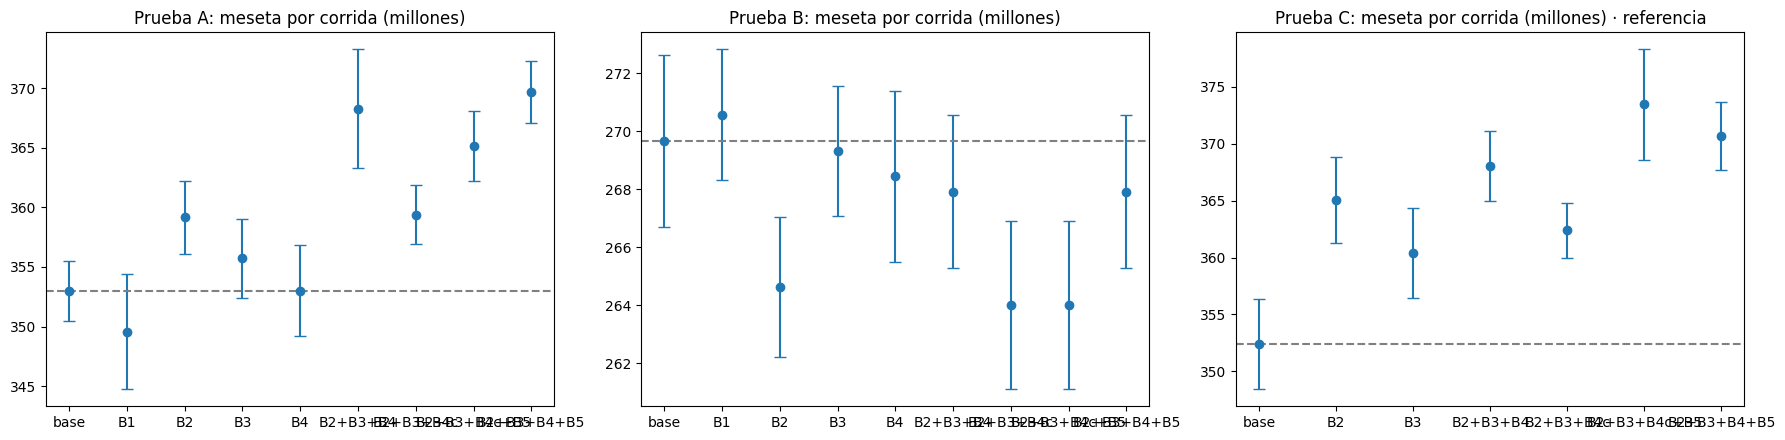

In [65]:
pruebas_graf = ['A', 'B'] + (['C'] if NECESITA_C else [])
fig, ejes = plt.subplots(1, len(pruebas_graf), figsize=(6 * len(pruebas_graf), 4.5))
for eje, prueba in zip(np.atleast_1d(ejes), pruebas_graf):
    ns = [n for n in ['base'] + NOMBRES if (n, prueba) in por_semilla]
    medias = [por_semilla[(n, prueba)].mean() / 1e6 for n in ns]
    desvios = [por_semilla[(n, prueba)].std(ddof=1) / 1e6 if len(SEMILLAS_A_USAR) > 1 else 0 for n in ns]
    eje.errorbar(ns, medias, yerr=desvios, fmt='o', capsize=4)
    eje.axhline(medias[0], linestyle='--', color='gray')
    eje.set_title(f'Prueba {prueba}: meseta por corrida (millones)' + (' · referencia' if prueba == 'C' else ''))
plt.tight_layout()
plt.show()

## 11. Elección (la decide el usuario)

- **A + B** en el N sugerido de cada corrida (promedio de los N de A y B, redondeado a 500, entre 8.000 y 15.000), y diferencia contra la base. C se muestra en el mismo N, como referencia.
- **Combinaciones:** se agregan a `COMBINACIONES` y se vuelve a correr el notebook. Solo se entrena lo nuevo.
- **Submit:** si una combinación le gana a la referencia, se confirma con el público. En el `03`: `BLOQUES = '<nombre>'` y `N_ENVIOS = 12_000` (decisión del 2026-10-05).

In [66]:
filas = []
for nombre in ['base'] + NOMBRES:
    r = resumen.query('nombre == @nombre').set_index('prueba')
    n = int(np.clip(round((r.loc['A', 'N_meseta'] + r.loc['B', 'N_meseta']) / 2 / 500) * 500, 8_000, 15_000))
    gA, gB = promedios[(nombre, 'A')][n - 1], promedios[(nombre, 'B')][n - 1]
    filas.append({'nombre': nombre, 'N_sugerido': n, 'A_en_N': gA / 1e6, 'B_en_N': gB / 1e6, 'A+B_en_N': (gA + gB) / 1e6,
                  'desvio_A+B': np.sqrt(r.loc[['A', 'B'], 'ganancia_desvio'].pow(2).sum()) / 1e6,
                  'C_en_N': promedios[(nombre, 'C')][n - 1] / 1e6 if (nombre, 'C') in promedios else np.nan})
eleccion = pd.DataFrame(filas)
eleccion['vs_base'] = eleccion['A+B_en_N'] - eleccion['A+B_en_N'].iloc[0]
if REFERENCIA:
    eleccion['vs_referencia'] = eleccion['A+B_en_N'] - eleccion.set_index('nombre').loc[REFERENCIA, 'A+B_en_N']
eleccion.style.format({c: '{:,.1f}' for c in ['A_en_N', 'B_en_N', 'A+B_en_N', 'desvio_A+B', 'C_en_N', 'vs_base', 'vs_referencia']
                       if c in eleccion} | {'N_sugerido': '{:,}'})

,nombre,N_sugerido,A_en_N,B_en_N,A+B_en_N,desvio_A+B,C_en_N,vs_base,vs_referencia
0,base,"10,500",347.3,261.4,608.6,3.9,347.7,0.0,-17.8
1,B1,"9,000",344.5,268.8,613.4,5.3,nan,4.7,-13.1
2,B2,"9,500",355.7,263.2,619.0,3.9,361.0,10.3,-7.5
3,B3,"9,500",353.0,267.9,620.8,4.0,354.4,12.2,-5.6
4,B4,"9,000",351.0,263.8,614.8,4.8,nan,6.2,-11.7
5,B2+B3+B4,"9,500",364.2,262.2,626.5,5.6,363.4,17.8,0.0
6,B2+B3+B4c,"9,500",355.1,261.2,616.3,3.8,358.1,7.7,-10.1
7,B2+B3+B4c+B5,"9,500",361.6,261.2,622.8,4.1,367.0,14.2,-3.6
8,B2+B3+B4+B5,"9,000",366.5,264.8,631.3,3.7,358.9,22.7,4.8


## 12. Cierre

- **Registro:** anotar en `decisiones.md` el experimento #3 (resumen por bloque en A, B y C, y la comparación pareada) y qué bloques se adoptan.
- **Combinaciones:** `COMBINACIONES = [...]` y correr de nuevo.
- **Submit:** en el `03`, `BLOQUES = '<nombre>'`, `VARIANTE` = la base del `05` y `N_ENVIOS = 12_000`.